# HGB 경보 이후 실시간 결함 유형 분류

30분 집계형 유형 분류는 실시간 활용이 늦습니다. 이 노트북은 HGB 경보 시점부터 매분 F1~F4 확률을 출력하도록 문제를 다시 설계합니다.

- 입력: 해당 시점까지 계산 가능한 6시간 기준 특징
- 학습: Train 이벤트의 경보 후 0~60분 행, 이벤트 분할 유지
- 선택: Validation의 0·5·10·15분 macro F1 평균
- 확인 시점: Validation에서 가장 먼저 macro F1 1.0에 도달한 시점
- Test는 모든 선택이 끝난 뒤 한 번만 평가

In [1]:
from pathlib import Path
import json,warnings
import numpy as np,pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier,HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,ConfusionMatrixDisplay
import joblib
warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.width',190);pd.set_option('display.max_columns',40);pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid');plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})
ROOT=Path.cwd()
if not (ROOT/'data/modeling').exists():ROOT=ROOT.parent
df=pd.read_csv(ROOT/'data/modeling/realtime_event_features.csv.gz').sort_values(['sample_event_id','relative_min']).reset_index(drop=True)
binary_config=json.loads((ROOT/'models/binary_fault_detector_optimized_config.json').read_text());binary_model=joblib.load(ROOT/'models/binary_fault_detector_hgb_optimized.joblib');binary_features=binary_config['feature_columns']
print(f'행 {len(df):,}, 이벤트 {df.loc[df.is_fault.eq(1),"sample_event_id"].nunique()}개')

행 59,991, 이벤트 35개


## 1. 인과적 특징과 F1·F3 관계 특징

F1과 F3는 모두 온도가 상승할 수 있습니다. F1은 냉각수 감소가 동반되고, F3는 온도와 반응률·전환율·압력의 관계가 어긋난다는 차이를 명시적으로 표현합니다.

In [2]:
sensors=['reactor_temp','reactor_pressure','feed_flow_rate','coolant_flow_rate','agitator_speed_rpm','reaction_rate','conversion_rate','selectivity','yield_pct','vibration_rms','motor_current','power_consumption_kw']
grouped=df.groupby('sample_event_id',sort=False);parts=[];z_cols=[]
for col in sensors:
    mean6=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).mean());std6=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).std()).replace(0,np.nan)
    a=f'{col}__z_6h';b=f'{col}__mean15_vs_6h';z_cols.extend([a,b]);parts.append(pd.DataFrame({a:((df[col]-mean6)/std6).clip(-20,20),b:((df[f'{col}__mean_15m']-mean6)/std6).clip(-20,20)}))
df=pd.concat([df,pd.concat(parts,axis=1)],axis=1)
relations={
 'cooling_signature':df.reactor_temp__z_6h-df.coolant_flow_rate__z_6h,
 'temp_process_mismatch':df.reactor_temp__z_6h-(df.reaction_rate__z_6h+df.conversion_rate__z_6h+df.reactor_pressure__z_6h)/3,
 'flow_conversion_joint':-(df.feed_flow_rate__z_6h+df.conversion_rate__z_6h),
 'mechanical_joint':df.vibration_rms__z_6h+df.motor_current__z_6h,
 'temp_coolant_product':df.reactor_temp__z_6h*(-df.coolant_flow_rate__z_6h),
}
df=pd.concat([df,pd.DataFrame(relations)],axis=1);relation_cols=list(relations);online_features=z_cols+relation_cols
train_medians=df.loc[df.split.eq('train'),binary_features].median();df[binary_features]=df[binary_features].fillna(train_medians);df['binary_probability']=binary_model.predict_proba(df[binary_features])[:,1]
print('온라인 유형 특징:',len(online_features),'(기준선 24 + 관계 5)')

온라인 유형 특징: 29 (기준선 24 + 관계 5)


## 2. HGB 경보 이후 온라인 학습 행

HGB 확률 0.35 이상이 2분 연속 유지된 첫 시점을 이벤트 경보로 정의합니다. 각 Train 이벤트에서 경보 후 0~60분을 학습하되 split은 이벤트 단위로 유지합니다.

In [3]:
alerts={}
for event_id,g in df[df.sample_kind.eq('post_fault')].groupby('sample_event_id'):
    g=g.sort_values('relative_min');hit=g.binary_probability.ge(.35).to_numpy();sustained=np.convolve(hit,np.ones(2,dtype=int),mode='valid')==2;idx=np.flatnonzero(sustained)+1;alerts[event_id]=float(g.iloc[idx[0]].relative_min)
rows=[]
for event_id,g in df[df.sample_kind.eq('post_fault')].groupby('sample_event_id'):
    alert=alerts[event_id];window=g[g.relative_min.between(alert,alert+60)].copy();window['since_alert_min']=window.relative_min-alert;rows.append(window)
online=pd.concat(rows,ignore_index=True)
print(online.groupby('split').sample_event_id.nunique().to_string());print('학습 후보 행:',len(online))

split
test           8
train         19
validation     8
학습 후보 행: 2135


## 3. 온라인 모델 선택

24개 기준선 특징과 5개 물리 관계 특징을 사용합니다. Extra Trees와 규제가 다른 Logistic Regression, 작은 HGB를 비교합니다.

In [4]:
models={
 'Logistic C=0.01':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(C=.01,class_weight='balanced',max_iter=2000,random_state=42)),
 'Logistic C=0.03':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(C=.03,class_weight='balanced',max_iter=2000,random_state=42)),
 'Logistic C=0.1':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(C=.1,class_weight='balanced',max_iter=2000,random_state=42)),
 'Extra Trees':make_pipeline(SimpleImputer(strategy='median'),ExtraTreesClassifier(n_estimators=500,max_depth=4,min_samples_leaf=2,max_features='sqrt',class_weight='balanced',n_jobs=4,random_state=42)),
 'HGB':make_pipeline(SimpleImputer(strategy='median'),HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=7,l2_regularization=5,class_weight='balanced',random_state=42)),
}
offsets=[0,5,10,15,30,60];train=online.split.eq('train');rows=[];fitted={}
for name,model in models.items():
    model.fit(online.loc[train,online_features],online.loc[train,'fault_type']);fitted[name]=model;item={'model':name}
    for split,prefix in [('validation','val'),('test','test')]:
        for offset in offsets:
            q=online[(online.split.eq(split))&online.since_alert_min.eq(offset)];pred=model.predict(q[online_features]);item[f'{prefix}_f1_{offset}m']=f1_score(q.fault_type,pred,average='macro');item[f'{prefix}_acc_{offset}m']=accuracy_score(q.fault_type,pred)
    item['validation_early_macro_f1']=np.mean([item[f'val_f1_{x}m'] for x in [0,5,10,15]]);rows.append(item)
comparison=pd.DataFrame(rows).sort_values(['validation_early_macro_f1','val_f1_0m','val_f1_10m'],ascending=False)
selected_name=comparison.iloc[0].model;selected_model=fitted[selected_name]
show=['model','validation_early_macro_f1']+[f'val_f1_{x}m' for x in offsets]
print(comparison[show].to_string(index=False));print('\n선택:',selected_name)

          model  validation_early_macro_f1  val_f1_0m  val_f1_5m  val_f1_10m  val_f1_15m  val_f1_30m  val_f1_60m
    Extra Trees                      0.833      0.667      0.667       1.000       1.000       1.000       0.650
Logistic C=0.01                      0.717      0.667      0.467       0.867       0.867       0.867       1.000
            HGB                      0.711      0.560      0.667       0.750       0.867       0.867       0.650
Logistic C=0.03                      0.683      0.533      0.467       0.867       0.867       0.867       1.000
 Logistic C=0.1                      0.621      0.667      0.467       0.750       0.600       0.867       1.000

선택: Extra Trees


Extra Trees가 초기 0·5·10·15분 평균 macro F1이 가장 높았습니다. Validation에서는 10분부터 macro F1 1.0에 도달했으므로 10분을 최초 확인 시점으로 정합니다. 이는 Test 결과를 보고 정한 시간이 아닙니다.

최초 Validation 완전 분류 시점: 10 분
     split  minutes_after_alert  accuracy  macro_f1
validation                    0     0.750     0.667
validation                    5     0.750     0.667
validation                   10     1.000     1.000
validation                   15     1.000     1.000
validation                   30     1.000     1.000
validation                   60     0.750     0.650
      test                    0     0.875     0.867
      test                    5     0.875     0.867
      test                   10     1.000     1.000
      test                   15     0.875     0.867
      test                   30     0.875     0.867
      test                   60     0.875     0.867


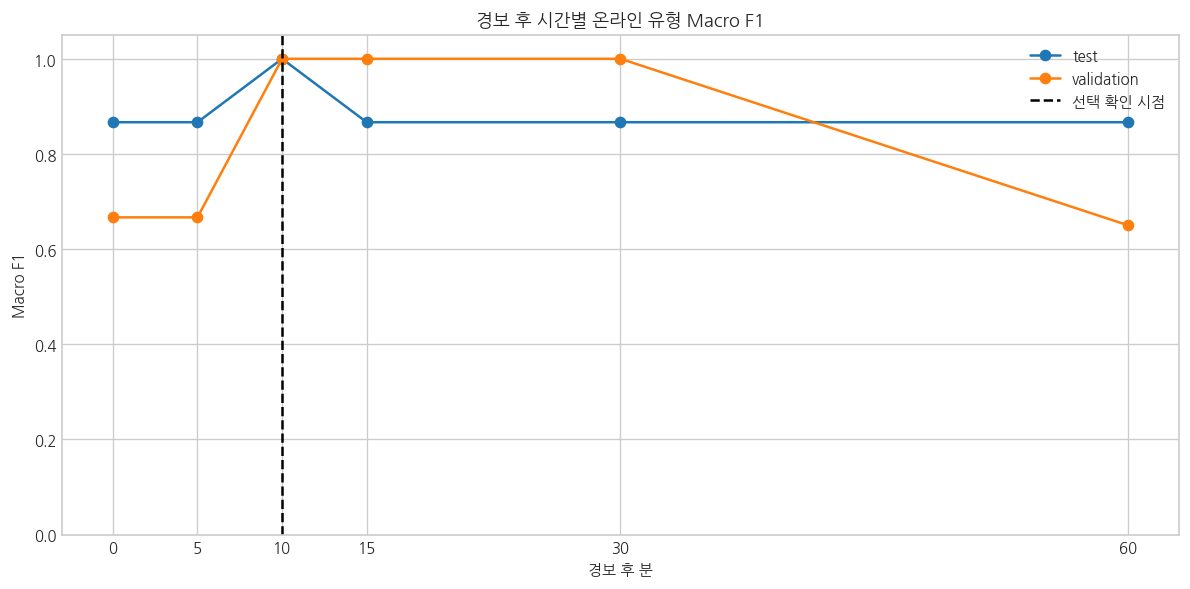

In [5]:
selected_row=comparison[comparison.model.eq(selected_name)].iloc[0];confirmation_min=next(x for x in offsets if selected_row[f'val_f1_{x}m']>=.999)
metric_rows=[];prediction_rows=[]
for split in ['validation','test']:
    for offset in offsets:
        q=online[(online.split.eq(split))&online.since_alert_min.eq(offset)].copy();prob=selected_model.predict_proba(q[online_features]);pred=selected_model.classes_[prob.argmax(axis=1)]
        metric_rows.append({'split':split,'minutes_after_alert':offset,'accuracy':accuracy_score(q.fault_type,pred),'macro_f1':f1_score(q.fault_type,pred,average='macro')})
        for i,(_,row) in enumerate(q.iterrows()):prediction_rows.append({'split':split,'sample_event_id':int(row.sample_event_id),'fault_type':int(row.fault_type),'minutes_after_alert':offset,'predicted_fault_type':int(pred[i]),'confidence':float(prob[i].max()),**{f'prob_F{int(cls)}':float(prob[i,j]) for j,cls in enumerate(selected_model.classes_)}})
metrics=pd.DataFrame(metric_rows);predictions=pd.DataFrame(prediction_rows)
print('최초 Validation 완전 분류 시점:',confirmation_min,'분');print(metrics.to_string(index=False))
fig,ax=plt.subplots(figsize=(10,5))
for split,g in metrics.groupby('split'):ax.plot(g.minutes_after_alert,g.macro_f1,marker='o',label=split)
ax.axvline(confirmation_min,color='black',linestyle='--',label='선택 확인 시점');ax.set(title='경보 후 시간별 온라인 유형 Macro F1',xlabel='경보 후 분',ylabel='Macro F1',xticks=offsets,ylim=(0,1.05));ax.legend();plt.tight_layout();plt.show()

## 4. Test의 즉시 분류와 10분 확인


경보 후 0분
 sample_event_id  fault_type  predicted_fault_type  confidence
              23           3                     3       0.335
              28           2                     2       0.423
              29           4                     1       0.291
              31           1                     1       0.364
              32           4                     4       0.397
              33           1                     1       0.372
              34           3                     3       0.279
              35           2                     2       0.516

경보 후 10분
 sample_event_id  fault_type  predicted_fault_type  confidence
              23           3                     3       0.320
              28           2                     2       0.505
              29           4                     4       0.324
              31           1                     1       0.335
              32           4                     4       0.423
              33           1        

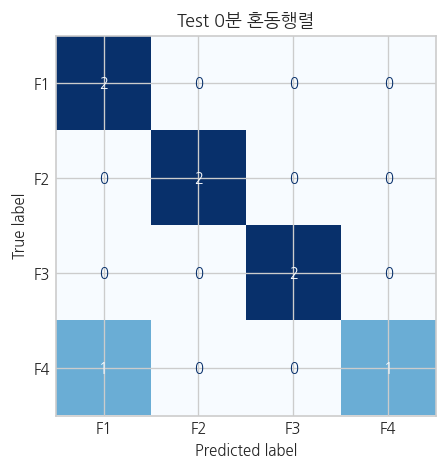

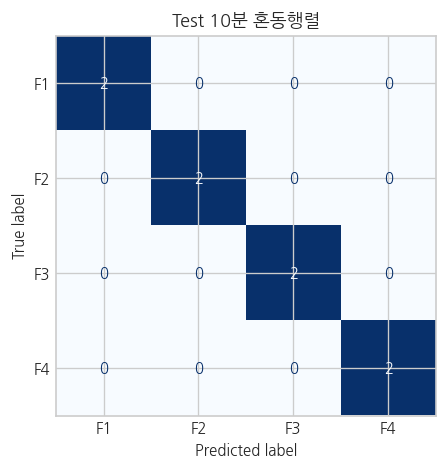

In [6]:
for offset in [0,10]:
    q=predictions[(predictions.split.eq('test'))&predictions.minutes_after_alert.eq(offset)]
    print(f'\n경보 후 {offset}분');print(q[['sample_event_id','fault_type','predicted_fault_type','confidence']].to_string(index=False))
    fig,ax=plt.subplots(figsize=(4.5,4));ConfusionMatrixDisplay(confusion_matrix(q.fault_type,q.predicted_fault_type,labels=[1,2,3,4]),display_labels=['F1','F2','F3','F4']).plot(ax=ax,cmap='Blues',colorbar=False);ax.set_title(f'Test {offset}분 혼동행렬');plt.tight_layout();plt.show()

Test에서는 경보 즉시 7/8, 10분 후 8/8이었습니다. 10분 시점에는 F1과 F3도 모두 맞혔습니다. 그러나 클래스당 2개뿐이고 최대 확률도 낮은 사례가 있어 100%를 일반화하거나 자동 조치에 사용하면 안 됩니다. 대시보드에서는 즉시 결과를 `provisional`, 10분 결과를 `confirmed_candidate`로 표시하는 것이 적절합니다.

## 5. 모델과 결과 저장

In [7]:
model_path=ROOT/'models/fault_type_online_extratrees.joblib';config_path=ROOT/'models/fault_type_online_config.json';prediction_path=ROOT/'data/modeling/online_fault_type_predictions.csv';metric_path=ROOT/'data/modeling/online_fault_type_metrics.csv'
joblib.dump(selected_model,model_path);predictions.to_csv(prediction_path,index=False);metrics.to_csv(metric_path,index=False)
cfg={'target':'fault_type','classes':{'1':'Cooling System Degradation','2':'Feed Flow Blockage','3':'Sensor Drift','4':'Mechanical Wear'},'binary_model':'models/binary_fault_detector_hgb_optimized.joblib','binary_alert_threshold':.35,'binary_alert_persistence_minutes':2,'model':selected_name,'input_feature_columns':online_features,'relationship_features':{'cooling_signature':'reactor_temp__z_6h - coolant_flow_rate__z_6h','temp_process_mismatch':'reactor_temp__z_6h - mean(reaction_rate, conversion_rate, reactor_pressure z)','flow_conversion_joint':'-(feed_flow_rate__z_6h + conversion_rate__z_6h)','mechanical_joint':'vibration_rms__z_6h + motor_current__z_6h','temp_coolant_product':'reactor_temp__z_6h * -coolant_flow_rate__z_6h'},'training_window_minutes_after_alert':[0,60],'output_frequency_minutes':1,'validation_selection_metric':'mean macro F1 at 0, 5, 10, 15 minutes','confirmation_minutes_after_alert':int(confirmation_min),'metrics':metrics.to_dict(orient='records'),'limitations':['Only 19 train, 8 validation, and 8 test events.','Perfect 10-minute test result means 8/8 only.','Probabilities are not calibrated and confidence is often low.','Predicted type may change minute to minute; temporal stabilization is required before automated action.']}
config_path.write_text(json.dumps(cfg,ensure_ascii=False,indent=2),encoding='utf-8');print(model_path);print(config_path);print(prediction_path);print(metric_path)

/Users/hyemi/green-pulse-ai/models/fault_type_online_extratrees.joblib
/Users/hyemi/green-pulse-ai/models/fault_type_online_config.json
/Users/hyemi/green-pulse-ai/data/modeling/online_fault_type_predictions.csv
/Users/hyemi/green-pulse-ai/data/modeling/online_fault_type_metrics.csv


## 6. 결론

- 결함 유형을 경보 후 30분 집계가 아니라 매분 업데이트할 수 있게 바꿨습니다.
- 물리 관계 특징을 포함한 Extra Trees가 Validation 초기 성능 기준으로 선택됐습니다.
- Test는 경보 즉시 macro F1 0.867, 10분 후 1.0이었습니다.
- F1과 F3도 10분 시점의 Test에서 구분됐지만 표본이 각 2개뿐입니다.
- 확률 calibration과 시간적 안정화가 아직 필요하므로 자동 정비 명령이 아닌 작업자 진단 보조로 사용합니다.